In [3]:

# ==========================================
# STEP 1: LIBRARIES IMPORT & GPU SETUP
# ==========================================

# Core Libraries
import os
import gc
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Image Processing
from PIL import Image

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Machine Learning Utilities
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Device Selection
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Same Random Seed as Sir's Notebook
torch.manual_seed(0)
np.random.seed(0)
random.seed(0)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(0)

# Memory Cleanup
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("Libraries imported successfully!")


Using device: cuda
GPU: Tesla T4
PyTorch Version: 2.11.0+cu130
CUDA Available: True
Libraries imported successfully!


In [4]:

# ==========================================
# STEP 2: DATASET LOADING
# ==========================================

# Dataset Path
DATASET_PATH = (
    "/kaggle/input/datasets/"
    "sanjitislamkafil/greenhouse-crop-weed-cvpr/"
    "cropped images"
)

# Check Dataset Path
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}"
    )

print("Dataset Path Exists:", os.path.exists(DATASET_PATH))

# Image Extensions
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

# Collect Image Paths and Labels
records = []

for group in ["crops", "weeds"]:

    group_path = os.path.join(DATASET_PATH, group)

    for class_name in sorted(os.listdir(group_path)):

        class_path = os.path.join(group_path, class_name)

        if not os.path.isdir(class_path):
            continue

        for root, dirs, files in os.walk(class_path):

            for file in files:

                if file.lower().endswith(IMAGE_EXTENSIONS):

                    image_path = os.path.join(root, file)

                    records.append({
                        "Image_Path": image_path,
                        "Label": class_name,
                        "Group": group
                    })

# Create DataFrame
df = pd.DataFrame(records)

# Class Names
class_names = sorted(df["Label"].unique().tolist())

# Class to Index Mapping
class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

df["Label_ID"] = df["Label"].map(class_to_idx)

# Dataset Summary
print("\nTOTAL CLASSES:", len(class_names))
print("TOTAL IMAGES:", len(df))

print("\nCLASS-WISE IMAGE COUNT:")
print(
    df["Label"].value_counts().sort_index().to_string()
)

print("\nDataset Loaded Successfully!")


Dataset Path Exists: True

TOTAL CLASSES: 14
TOTAL IMAGES: 28000

CLASS-WISE IMAGE COUNT:
Label
Blackbean          2000
Canola             2000
Corn               2000
Field Pea          2000
Flax               2000
Horseweed          2000
Kochia             2000
Lentil             2000
Palmer Amaranth    2000
Ragweed            2000
Redroot Pigweed    2000
Soybean            2000
Sugar beet         2000
Waterhemp          2000

Dataset Loaded Successfully!


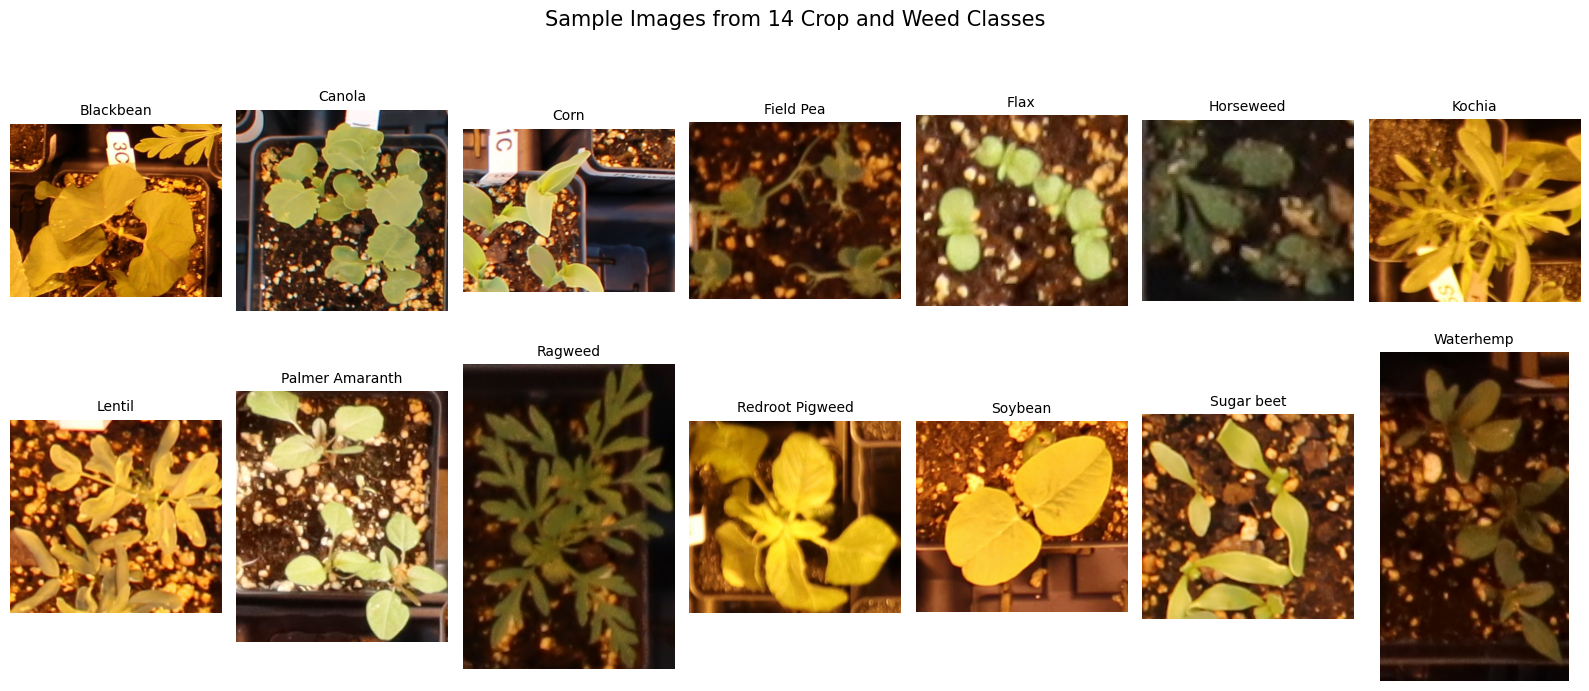

Sample Image Visualization Completed!


In [5]:

# ==========================================
# STEP 3: SAMPLE IMAGE VISUALIZATION
# ==========================================

fig, axes = plt.subplots(2, 7, figsize=(16, 7))

axes = axes.flatten()

for i, class_name in enumerate(class_names):

    # Select one image from each class
    sample = df[df["Label"] == class_name].sample(
        n=1, random_state=0
    ).iloc[0]

    # Load image
    img = Image.open(
        sample["Image_Path"]
    ).convert("RGB")

    # Display image
    axes[i].imshow(img)
    axes[i].set_title(class_name, fontsize=10)
    axes[i].axis("off")

plt.suptitle(
    "Sample Images from 14 Crop and Weed Classes",
    fontsize=15
)

plt.tight_layout()
plt.show()

print("Sample Image Visualization Completed!")


In [6]:

# ==========================================
# STEP 4: TRAIN / VALIDATION / TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["Label"]
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["Label"]
)

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Verify split
print("TRAINING IMAGES:", len(train_df))
print("VALIDATION IMAGES:", len(val_df))
print("TESTING IMAGES:", len(test_df))

print("\nTOTAL IMAGES:",
      len(train_df) + len(val_df) + len(test_df))

# Class-wise distribution
class_split = pd.DataFrame({
    "Training": train_df["Label"].value_counts(),
    "Validation": val_df["Label"].value_counts(),
    "Testing": test_df["Label"].value_counts()
}).fillna(0).astype(int)

print("\nCLASS-WISE DATASET SPLIT:")
print(class_split.to_string())

# Check file-path overlap
train_paths = set(train_df["Image_Path"])
val_paths = set(val_df["Image_Path"])
test_paths = set(test_df["Image_Path"])

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

print("\nDataset Split Completed Successfully!")
print("No file-path overlap between splits.")


TRAINING IMAGES: 19600
VALIDATION IMAGES: 4200
TESTING IMAGES: 4200

TOTAL IMAGES: 28000

CLASS-WISE DATASET SPLIT:
                 Training  Validation  Testing
Label                                         
Blackbean            1400         300      300
Canola               1400         300      300
Corn                 1400         300      300
Field Pea            1400         300      300
Flax                 1400         300      300
Horseweed            1400         300      300
Kochia               1400         300      300
Lentil               1400         300      300
Palmer Amaranth      1400         300      300
Ragweed              1400         300      300
Redroot Pigweed      1400         300      300
Soybean              1400         300      300
Sugar beet           1400         300      300
Waterhemp            1400         300      300

Dataset Split Completed Successfully!
No file-path overlap between splits.


In [7]:

# ==========================================
# STEP 5: IMAGE PREPROCESSING & DATALOADER
# ==========================================

# Image Configuration
IMG_SIZE = 128
BATCH_SIZE = 32

# Basic Transformation (Same as Sir)
basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

# Custom Dataset Class
class CropWeedDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        image_path = self.dataframe.loc[idx, "Image_Path"]
        label = self.dataframe.loc[idx, "Label_ID"]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


# Create Datasets
train_dataset = CropWeedDataset(
    train_df, transform=basic_transform
)

val_dataset = CropWeedDataset(
    val_df, transform=basic_transform
)

test_dataset = CropWeedDataset(
    test_df, transform=basic_transform
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

# Check One Batch
sample_images, sample_labels = next(iter(train_loader))

print("Preprocessing Completed!")

print("Training Images:", len(train_dataset))
print("Validation Images:", len(val_dataset))
print("Testing Images:", len(test_dataset))

print("\nTraining Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

print("\nImage Batch Shape:", sample_images.shape)
print("Label Batch Shape:", sample_labels.shape)

print(
    "Pixel Value Range:",
    sample_images.min().item(),
    "to",
    sample_images.max().item()
)


Preprocessing Completed!
Training Images: 19600
Validation Images: 4200
Testing Images: 4200

Training Batches: 613
Validation Batches: 132
Testing Batches: 132

Image Batch Shape: torch.Size([32, 3, 128, 128])
Label Batch Shape: torch.Size([32])
Pixel Value Range: 0.0 to 1.0


In [8]:

# ==========================================
# STEP 6: SIMPLE CNN MODEL ARCHITECTURE
# ==========================================

class SimpleCNN(nn.Module):

    def __init__(self, p_dropout=0.0):
        super().__init__()

        # Feature Extractor: 3 Convolution Layers
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        # Max Pooling
        self.pool = nn.MaxPool2d(2, 2)

        # Classification Layers
        self.dropout = nn.Dropout(p_dropout)
        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, len(class_names))

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# Create Model (Round 1: No Dropout)
model = SimpleCNN(p_dropout=0.0).to(device)

print(model)

# Total Trainable Parameters
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTotal Trainable Parameters:", f"{total_params:,}")

# Test Model Output
sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images.to(device)

with torch.no_grad():
    output = model(sample_images)

print("\nInput Shape:", sample_images.shape)
print("Output Shape:", output.shape)

print("\nCNN Model Created Successfully!")


SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=14, bias=True)
)

Total Trainable Parameters: 2,122,670

Input Shape: torch.Size([32, 3, 128, 128])
Output Shape: torch.Size([32, 14])

CNN Model Created Successfully!


In [9]:

# ==========================================
# STEP 7: ROUND 1 CNN TRAINING
# WITHOUT DATA AUGMENTATION
# ==========================================

def train_model(model, train_loader, val_loader,
                epochs=15, lr=1e-3):

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_acc = 0.0
    best_epoch = 0

    checkpoint_path = "/kaggle/working/round1_best.pth"

    for epoch in range(epochs):

        # -------- TRAINING --------
        model.train()

        running_loss, correct, total = 0.0, 0, 0

        for imgs, labels in train_loader:

            imgs = imgs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(imgs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        # -------- VALIDATION --------
        model.eval()

        running_loss, correct, total = 0.0, 0, 0

        with torch.no_grad():

            for imgs, labels in val_loader:

                imgs = imgs.to(device)
                labels = labels.to(device)

                outputs = model(imgs)
                loss = criterion(outputs, labels)

                running_loss += loss.item() * imgs.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)

        val_loss = running_loss / total
        val_acc = correct / total

        # Record History
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # Save Best Model
        if val_acc > best_val_acc:

            best_val_acc = val_acc
            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

        print(
            f"Epoch {epoch+1:2d}/{epochs} "
            f"train_loss={train_loss:.3f} "
            f"train_acc={train_acc:.3f} | "
            f"val_loss={val_loss:.3f} "
            f"val_acc={val_acc:.3f}"
        )

    # Load Best Model
    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )

    print("\n================================")
    print("ROUND 1 TRAINING COMPLETED")
    print("================================")

    print("Best Epoch:", best_epoch)
    print(
        "Best Validation Accuracy:",
        f"{best_val_acc*100:.2f}%"
    )

    print("Best Model Saved Successfully!")
    print("Checkpoint:", checkpoint_path)

    return history


# Start Round 1 Training
history_plain = train_model(
    model,
    train_loader,
    val_loader,
    epochs=15,
    lr=0.001
)


Epoch  1/15 train_loss=2.085 train_acc=0.293 | val_loss=1.495 val_acc=0.492
Epoch  2/15 train_loss=1.122 train_acc=0.619 | val_loss=0.955 val_acc=0.675
Epoch  3/15 train_loss=0.640 train_acc=0.786 | val_loss=0.838 val_acc=0.715
Epoch  4/15 train_loss=0.356 train_acc=0.882 | val_loss=0.704 val_acc=0.780
Epoch  5/15 train_loss=0.183 train_acc=0.939 | val_loss=0.703 val_acc=0.804
Epoch  6/15 train_loss=0.121 train_acc=0.961 | val_loss=0.904 val_acc=0.784
Epoch  7/15 train_loss=0.081 train_acc=0.974 | val_loss=0.937 val_acc=0.782
Epoch  8/15 train_loss=0.066 train_acc=0.977 | val_loss=0.963 val_acc=0.805
Epoch  9/15 train_loss=0.070 train_acc=0.978 | val_loss=0.902 val_acc=0.809
Epoch 10/15 train_loss=0.048 train_acc=0.984 | val_loss=0.983 val_acc=0.812
Epoch 11/15 train_loss=0.050 train_acc=0.983 | val_loss=0.998 val_acc=0.802
Epoch 12/15 train_loss=0.055 train_acc=0.982 | val_loss=1.024 val_acc=0.796
Epoch 13/15 train_loss=0.049 train_acc=0.984 | val_loss=1.047 val_acc=0.811
Epoch 14/15 

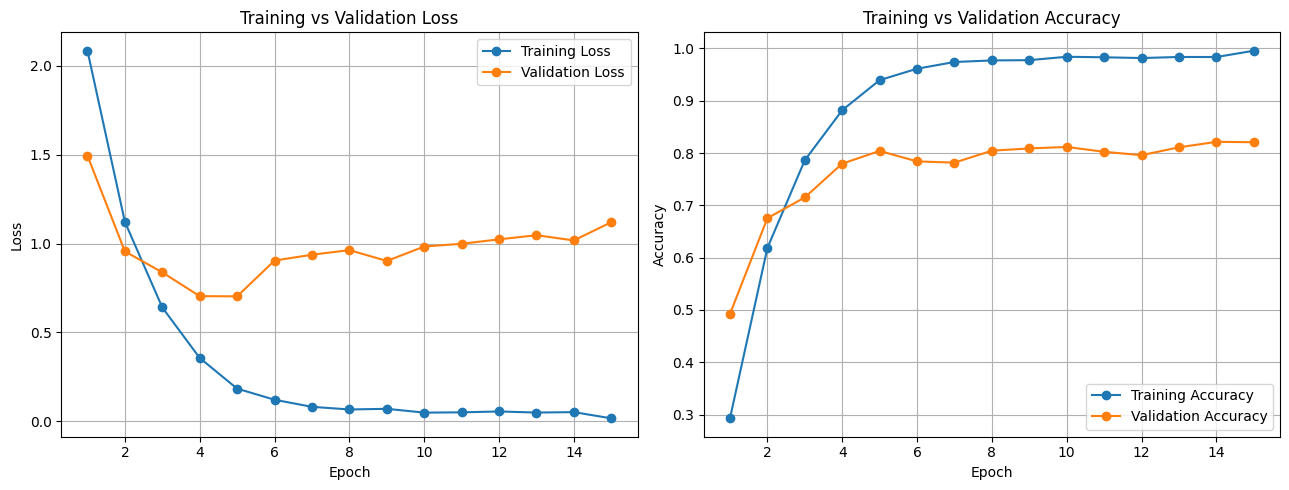

Best Epoch: 14
Best Validation Accuracy: 82.14%
Final Training Accuracy: 99.56%

Round 1 Graph Saved Successfully!


In [10]:

# ==========================================
# STEP 8: ROUND 1 RESULT VISUALIZATION
# ==========================================

epochs = range(1, len(history_plain["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Training vs Validation Loss
axes[0].plot(
    epochs, history_plain["train_loss"],
    marker="o", label="Training Loss"
)

axes[0].plot(
    epochs, history_plain["val_loss"],
    marker="o", label="Validation Loss"
)

axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Training vs Validation Accuracy
axes[1].plot(
    epochs, history_plain["train_acc"],
    marker="o", label="Training Accuracy"
)

axes[1].plot(
    epochs, history_plain["val_acc"],
    marker="o", label="Validation Accuracy"
)

axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

# Save Graph for Assignment Report
plt.savefig(
    "/kaggle/working/round1_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Best Epoch:", np.argmax(history_plain["val_acc"]) + 1)

print(
    "Best Validation Accuracy:",
    f"{max(history_plain['val_acc'])*100:.2f}%"
)

print(
    "Final Training Accuracy:",
    f"{history_plain['train_acc'][-1]*100:.2f}%"
)

print("\nRound 1 Graph Saved Successfully!")


In [11]:

# ==========================================
# STEP 9: ROUND 2 DATA AUGMENTATION
# ==========================================

# Training Transformation with Augmentation
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor()
])

# Clean Validation Transformation
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

# Create Augmented Training Dataset
train_dataset_aug = CropWeedDataset(
    train_df,
    transform=train_transform
)

# Create Augmented Training DataLoader
train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

# Keep Validation Data Clean
val_loader_clean = val_loader

# Create Fresh Model with Dropout
model_aug = SimpleCNN(p_dropout=0.5).to(device)

# Check Augmented Batch
sample_aug_images, sample_aug_labels = next(
    iter(train_loader_aug)
)

print("Augmented Training Pipeline Ready!")

print("Training Images:", len(train_dataset_aug))
print("Validation Images:", len(val_dataset))

print("Training Batches:", len(train_loader_aug))
print("Validation Batches:", len(val_loader_clean))

print("\nImage Batch Shape:", sample_aug_images.shape)
print("Label Batch Shape:", sample_aug_labels.shape)

print("\nDropout:", model_aug.dropout)


Augmented Training Pipeline Ready!
Training Images: 19600
Validation Images: 4200
Training Batches: 613
Validation Batches: 132

Image Batch Shape: torch.Size([32, 3, 128, 128])
Label Batch Shape: torch.Size([32])

Dropout: Dropout(p=0.5, inplace=False)


In [12]:

# ==========================================
# STEP 10: ROUND 2 MODEL TRAINING
# ==========================================

history_aug = train_model(
    model_aug,
    train_loader_aug,
    val_loader_clean,
    epochs=30
)

# Plot Training vs Validation Performance
plot_history(
    history_aug,
    "Round 2 — Augmentation + Dropout"
)


Epoch  1/30 train_loss=2.401 train_acc=0.186 | val_loss=2.017 val_acc=0.316
Epoch  2/30 train_loss=1.746 train_acc=0.417 | val_loss=1.372 val_acc=0.520
Epoch  3/30 train_loss=1.378 train_acc=0.534 | val_loss=1.053 val_acc=0.638
Epoch  4/30 train_loss=1.197 train_acc=0.590 | val_loss=1.032 val_acc=0.653
Epoch  5/30 train_loss=1.067 train_acc=0.633 | val_loss=0.900 val_acc=0.689
Epoch  6/30 train_loss=0.972 train_acc=0.663 | val_loss=0.752 val_acc=0.740
Epoch  7/30 train_loss=0.900 train_acc=0.688 | val_loss=0.797 val_acc=0.733
Epoch  8/30 train_loss=0.848 train_acc=0.704 | val_loss=0.676 val_acc=0.764
Epoch  9/30 train_loss=0.794 train_acc=0.721 | val_loss=0.656 val_acc=0.772
Epoch 10/30 train_loss=0.745 train_acc=0.738 | val_loss=0.641 val_acc=0.782
Epoch 11/30 train_loss=0.726 train_acc=0.747 | val_loss=0.600 val_acc=0.795
Epoch 12/30 train_loss=0.693 train_acc=0.756 | val_loss=0.552 val_acc=0.816
Epoch 13/30 train_loss=0.668 train_acc=0.766 | val_loss=0.643 val_acc=0.778
Epoch 14/30 

NameError: name 'plot_history' is not defined

Round 1 Model Saved Successfully!
Round 2 Model Saved Successfully!


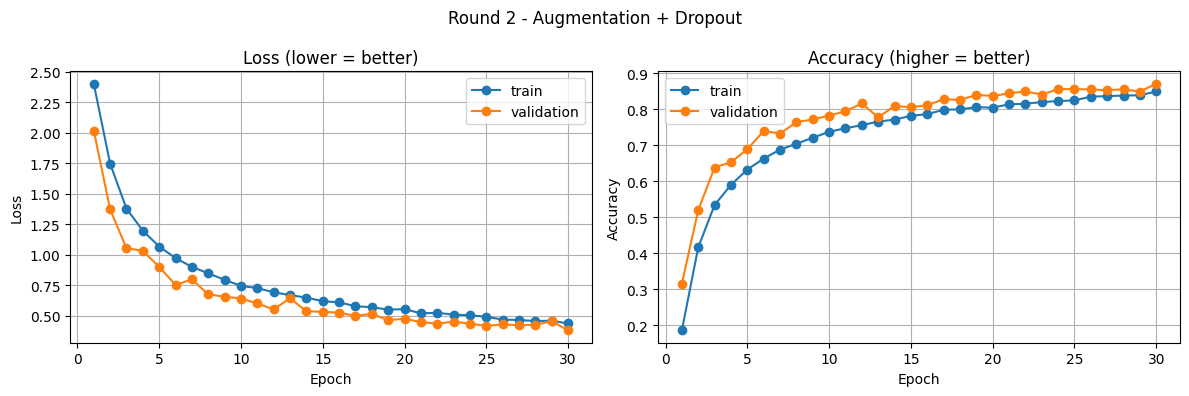


Best Epoch: 30
Best Validation Accuracy: 87.12%

Round 2 Analysis Completed!


In [13]:

# ==========================================
# STEP 11: SAVE MODELS AND PLOT ROUND 2
# ==========================================

# Save Round 1 Model (Restore its checkpoint)
torch.save(
    model.state_dict(),
    "/kaggle/working/round1_best.pth"
)

# Save Round 2 Model
torch.save(
    model_aug.state_dict(),
    "/kaggle/working/round2_best.pth"
)

print("Round 1 Model Saved Successfully!")
print("Round 2 Model Saved Successfully!")


# Plot History Function (Same as Sir)
def plot_history(history, title=""):

    epochs = range(1, len(history["train_loss"]) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # Loss Graph
    ax1.plot(epochs, history["train_loss"], "o-", label="train")
    ax1.plot(epochs, history["val_loss"], "o-", label="validation")

    ax1.set_title("Loss (lower = better)")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True)

    # Accuracy Graph
    ax2.plot(epochs, history["train_acc"], "o-", label="train")
    ax2.plot(epochs, history["val_acc"], "o-", label="validation")

    ax2.set_title("Accuracy (higher = better)")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy")
    ax2.legend()
    ax2.grid(True)

    fig.suptitle(title)
    plt.tight_layout()

    plt.savefig(
        "/kaggle/working/round2_training_curves.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# Plot Round 2 Results
plot_history(
    history_aug,
    "Round 2 - Augmentation + Dropout"
)

print("\nBest Epoch:",
      np.argmax(history_aug["val_acc"]) + 1)

print("Best Validation Accuracy:",
      f"{max(history_aug['val_acc'])*100:.2f}%")

print("\nRound 2 Analysis Completed!")


FINAL TEST EVALUATION
Total Test Images: 4200
Correct Predictions: 3644
Incorrect Predictions: 556
Test Accuracy: 86.76%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Class 0       0.85      0.87      0.86       300
     Class 1       0.84      0.91      0.88       300
     Class 2       0.88      0.94      0.91       300
     Class 3       0.83      0.99      0.90       300
     Class 4       0.91      0.82      0.86       300
     Class 5       0.96      0.99      0.97       300
     Class 6       0.88      0.94      0.91       300
     Class 7       0.95      0.93      0.94       300
     Class 8       0.66      0.71      0.69       300
     Class 9       0.99      0.89      0.94       300
    Class 10       0.78      0.81      0.80       300
    Class 11       0.91      0.80      0.85       300
    Class 12       0.94      0.88      0.91       300
    Class 13       0.79      0.66      0.72       300

    accuracy                           0.87 

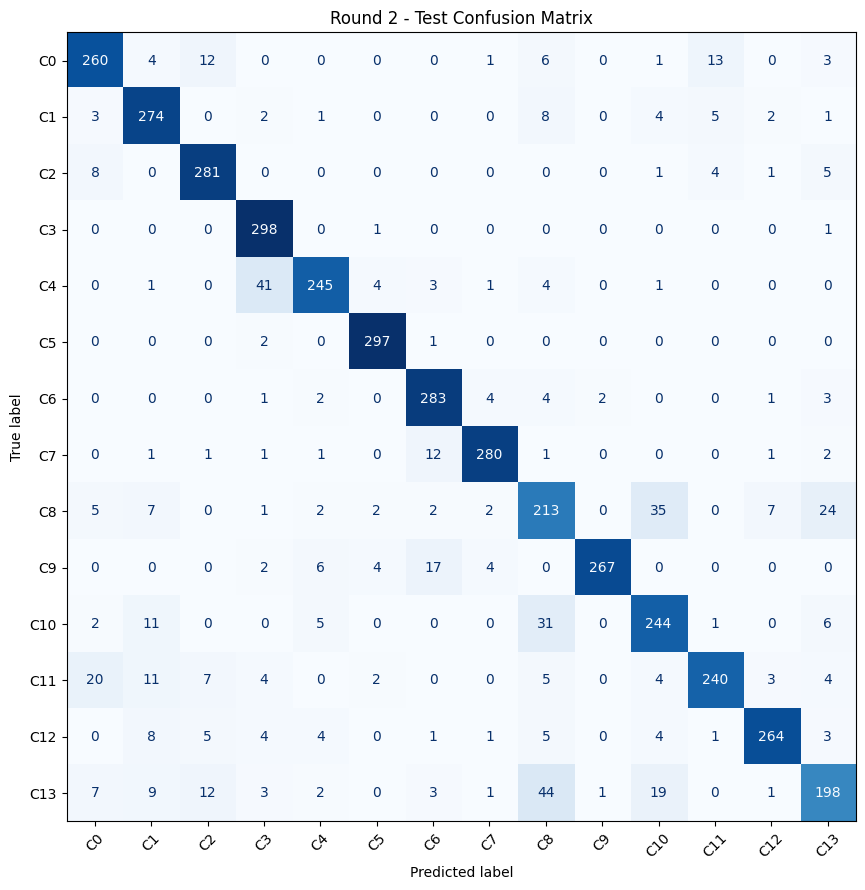


Test Evaluation Completed Successfully!


In [14]:

# ==========================================
# STEP 12: FINAL TEST DATASET EVALUATION
# ==========================================

import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load Best Round 2 Model
model_aug.load_state_dict(
    torch.load(
        "/kaggle/working/round2_best.pth",
        map_location=device
    )
)

model_aug.eval()

all_labels = []
all_predictions = []

correct = 0
total = 0

# Evaluate on Test Dataset
with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_aug(images)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())


# Calculate Test Accuracy
test_accuracy = 100 * correct / total

print("====================================")
print("FINAL TEST EVALUATION")
print("====================================")

print("Total Test Images:", total)

print("Correct Predictions:", correct)

print("Incorrect Predictions:", total - correct)

print(f"Test Accuracy: {test_accuracy:.2f}%")


# Classification Report
class_ids = sorted(
    set(all_labels) | set(all_predictions)
)

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=class_ids,
        target_names=[f"Class {i}" for i in class_ids],
        zero_division=0
    )
)


# Confusion Matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=class_ids
)

fig, ax = plt.subplots(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[f"C{i}" for i in class_ids]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

plt.title("Round 2 - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "/kaggle/working/round2_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nTest Evaluation Completed Successfully!")


ROUND 1 VS ROUND 2 COMPARISON
Round 1 Test Accuracy: 80.69%
Round 2 Test Accuracy: 86.76%

Accuracy Improvement: +6.07 percentage points


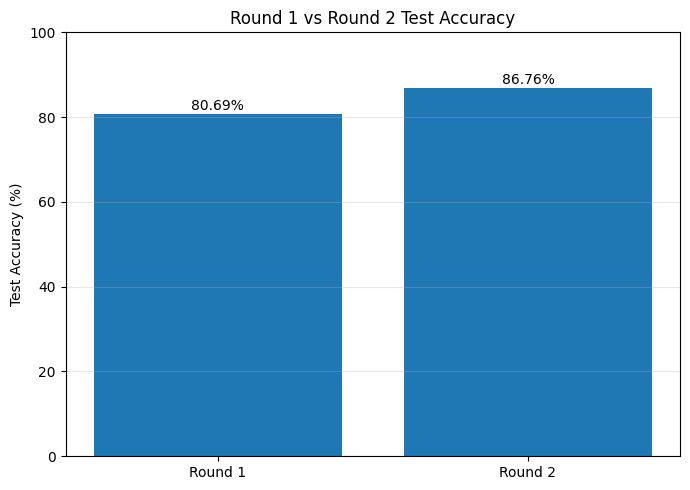


Model Comparison Completed!


In [15]:

# ==========================================
# STEP 13: ROUND 1 VS ROUND 2 COMPARISON
# ==========================================

# Load Both Best Models
model.load_state_dict(
    torch.load(
        "/kaggle/working/round1_best.pth",
        map_location=device,
        weights_only=True
    )
)

model_aug.load_state_dict(
    torch.load(
        "/kaggle/working/round2_best.pth",
        map_location=device,
        weights_only=True
    )
)


# Evaluation Function
def evaluate_accuracy(model, loader):

    model.eval()

    correct = 0
    total = 0

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


# Evaluate Both Models on Same Test Dataset
round1_test_acc = evaluate_accuracy(model, test_loader)

round2_test_acc = evaluate_accuracy(model_aug, test_loader)


# Comparison
print("====================================")
print("ROUND 1 VS ROUND 2 COMPARISON")
print("====================================")

print(f"Round 1 Test Accuracy: {round1_test_acc:.2f}%")
print(f"Round 2 Test Accuracy: {round2_test_acc:.2f}%")

improvement = round2_test_acc - round1_test_acc

print(f"\nAccuracy Improvement: {improvement:+.2f} percentage points")


# Comparison Graph
rounds = ["Round 1", "Round 2"]
accuracies = [round1_test_acc, round2_test_acc]

plt.figure(figsize=(7, 5))

bars = plt.bar(rounds, accuracies)

plt.title("Round 1 vs Round 2 Test Accuracy")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, accuracies):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/round_comparison.png",
    dpi=300
)

plt.show()

print("\nModel Comparison Completed!")


CLASS ID MAPPING
0: Blackbean
1: Canola
2: Corn
3: Field Pea
4: Flax
5: Horseweed
6: Kochia
7: Lentil
8: Palmer Amaranth
9: Ragweed
10: Redroot Pigweed
11: Soybean
12: Sugar beet
13: Waterhemp

FINAL CLASSIFICATION REPORT
                 precision    recall  f1-score   support

      Blackbean     0.8525    0.8667    0.8595       300
         Canola     0.8405    0.9133    0.8754       300
           Corn     0.8836    0.9367    0.9094       300
      Field Pea     0.8301    0.9933    0.9044       300
           Flax     0.9142    0.8167    0.8627       300
      Horseweed     0.9581    0.9900    0.9738       300
         Kochia     0.8789    0.9433    0.9100       300
         Lentil     0.9524    0.9333    0.9428       300
Palmer Amaranth     0.6636    0.7100    0.6860       300
        Ragweed     0.9889    0.8900    0.9368       300
Redroot Pigweed     0.7796    0.8133    0.7961       300
        Soybean     0.9091    0.8000    0.8511       300
     Sugar beet     0.9429    0.8800

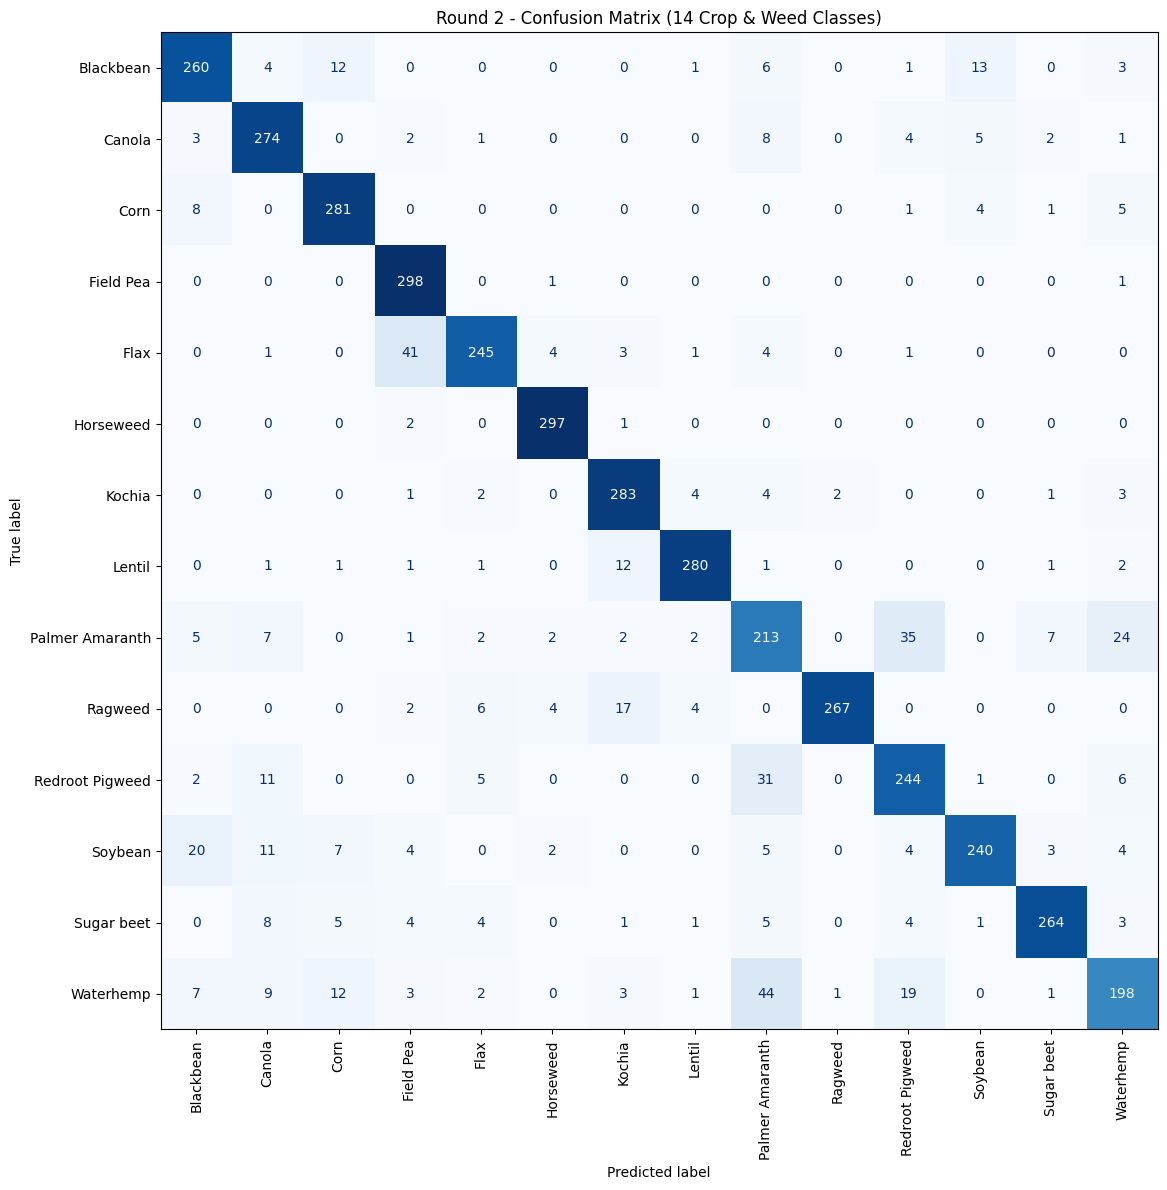


Final Class-wise Analysis Completed!


In [16]:

# ==========================================
# STEP 14: FINAL CLASS-WISE RESULT ANALYSIS
# ==========================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Actual Class Names
labels = list(range(len(class_names)))

print("CLASS ID MAPPING")
print("==============================")

for i, name in enumerate(class_names):
    print(f"{i}: {name}")


# Classification Report
report = classification_report(
    all_labels,
    all_predictions,
    labels=labels,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\nFINAL CLASSIFICATION REPORT")
print("==============================")
print(report)


# Save Classification Report
with open(
    "/kaggle/working/final_classification_report.txt",
    "w"
) as f:
    f.write(report)


# Named Confusion Matrix
cm_named = confusion_matrix(
    all_labels,
    all_predictions,
    labels=labels
)

fig, ax = plt.subplots(figsize=(15, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_named,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

plt.title(
    "Round 2 - Confusion Matrix (14 Crop & Weed Classes)"
)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/final_named_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFinal Class-wise Analysis Completed!")


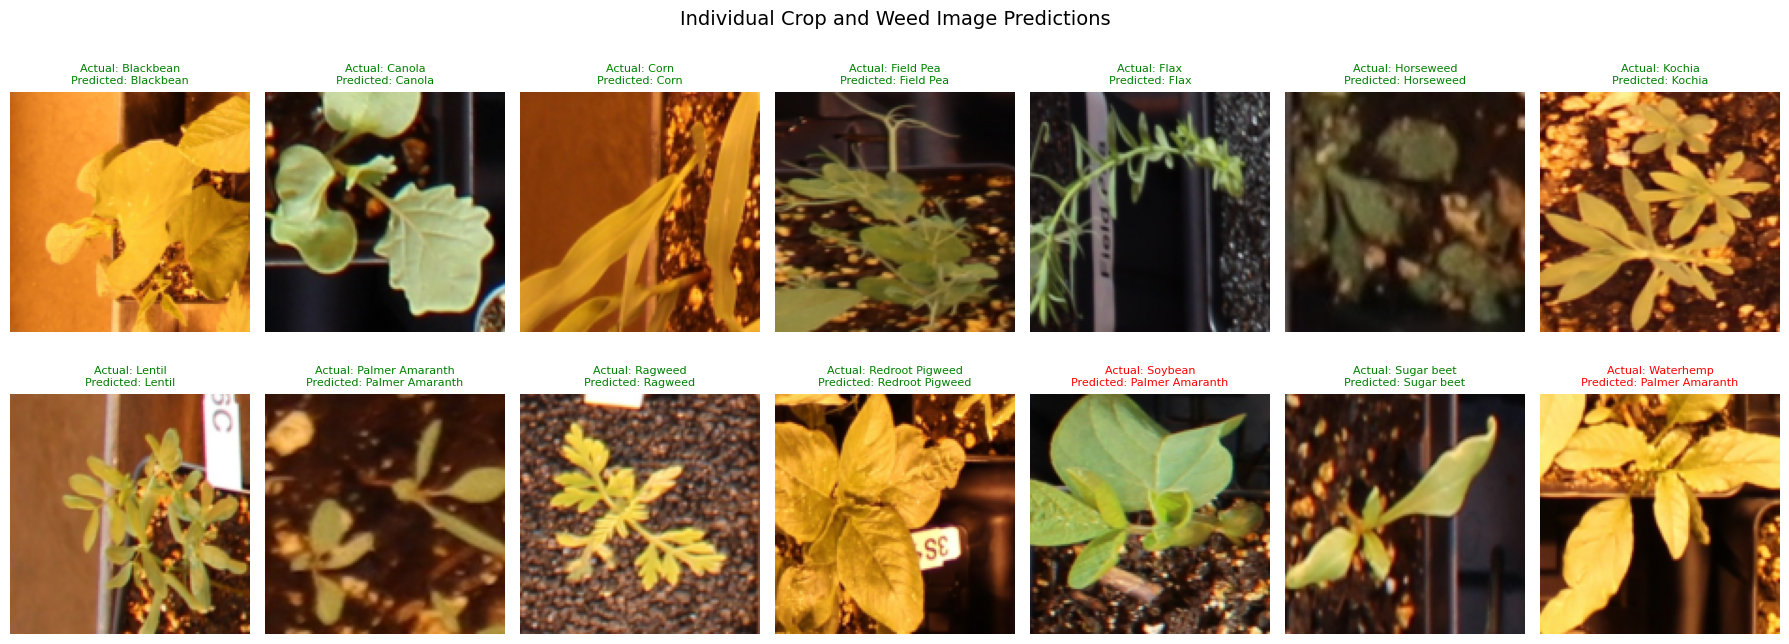

Individual Prediction Completed!
Correct Predictions: 12 / 14


In [17]:

# ==========================================
# STEP 15: INDIVIDUAL IMAGE PREDICTION
# ==========================================

import random

# Select One Random Test Image from Each Class
selected_indices = []

for class_id in range(len(class_names)):

    class_indices = test_dataset.dataframe.index[
        test_dataset.dataframe["Label_ID"] == class_id
    ].tolist()

    selected_indices.append(random.choice(class_indices))


# Load Selected Images
sample_images = torch.stack([
    test_dataset[i][0] for i in selected_indices
])

actual_labels = torch.stack([
    test_dataset[i][1] for i in selected_indices
])

# Model Prediction
model_aug.eval()

with torch.inference_mode():

    outputs = model_aug(sample_images.to(device))

    predicted_labels = outputs.argmax(dim=1).cpu()


# Visualize Predictions
fig, axes = plt.subplots(2, 7, figsize=(18, 7))

for i, ax in enumerate(axes.flat):

    image = sample_images[i].permute(1, 2, 0).numpy()

    actual = actual_labels[i].item()
    predicted = predicted_labels[i].item()

    ax.imshow(image)

    ax.set_title(
        f"Actual: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}",
        color="green" if actual == predicted else "red",
        fontsize=8
    )

    ax.axis("off")

plt.suptitle(
    "Individual Crop and Weed Image Predictions",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/individual_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Individual Prediction Completed!")
print(
    "Correct Predictions:",
    (actual_labels == predicted_labels).sum().item(),
    "/",
    len(class_names)
)


In [18]:

# ==========================================
# STEP 16: FINAL MODEL & RESULTS SAVING
# ==========================================

import os
import json
import zipfile

# 1. Save Best Round 2 Model
final_model_path = (
    "/kaggle/working/final_crop_weed_cnn.pth"
)

torch.save(
    model_aug.state_dict(),
    final_model_path
)

print("Final CNN Model Saved Successfully!")


# 2. Save Class Names
class_mapping = {
    str(i): str(name)
    for i, name in enumerate(class_names)
}

with open(
    "/kaggle/working/class_names.json",
    "w"
) as f:
    json.dump(class_mapping, f, indent=4)


# 3. Save Model Information
model_info = {
    "model": "SimpleCNN",
    "dataset": "Greenhouse Crop Weed CVPR",
    "image_size": IMG_SIZE,
    "num_classes": len(class_names),
    "dropout": 0.5,
    "round1_test_accuracy": round1_test_acc,
    "round2_test_accuracy": round2_test_acc,
    "best_round2_validation_accuracy":
        max(history_aug["val_acc"]) * 100,
    "test_images": len(test_dataset),
    "classes": list(map(str, class_names))
}

with open(
    "/kaggle/working/model_information.json",
    "w"
) as f:
    json.dump(model_info, f, indent=4)


# 4. Create Final Results Summary
summary = f"""
CROP AND WEED CLASSIFICATION
================================

Dataset Images: 28000
Number of Classes: 14

Training Images: 19600
Validation Images: 4200
Testing Images: 4200

CNN Architecture: SimpleCNN

ROUND 1
----------------
Test Accuracy: {round1_test_acc:.2f}%

ROUND 2
----------------
Best Validation Accuracy:
{max(history_aug['val_acc'])*100:.2f}%

Test Accuracy: {round2_test_acc:.2f}%

Accuracy Improvement:
{round2_test_acc-round1_test_acc:.2f} Percentage Points

FINAL MODEL
----------------
Model: SimpleCNN
Dropout: 0.5
Input Size: 128x128
Output Classes: 14
"""

with open(
    "/kaggle/working/final_results_summary.txt",
    "w"
) as f:
    f.write(summary)


# 5. Package All Important Files
files_to_package = [
    "final_crop_weed_cnn.pth",
    "round1_best.pth",
    "round2_best.pth",
    "class_names.json",
    "model_information.json",
    "final_results_summary.txt",
    "final_classification_report.txt",
    "round1_training_curves.png",
    "round2_training_curves.png",
    "round_comparison.png",
    "final_named_confusion_matrix.png",
    "individual_predictions.png"
]

zip_path = "/kaggle/working/final_assignment_package.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zipf:

    for filename in files_to_package:

        path = "/kaggle/working/" + filename

        if os.path.exists(path):
            zipf.write(path, arcname=filename)
            print("Added:", filename)
        else:
            print("Not Found:", filename)


print("\n================================")
print("FINAL SAVING COMPLETED!")
print("================================")

print("Model:", final_model_path)
print("Package:", zip_path)

print(
    "Package Size:",
    f"{os.path.getsize(zip_path)/(1024*1024):.2f} MB"
)


Final CNN Model Saved Successfully!
Added: final_crop_weed_cnn.pth
Added: round1_best.pth
Added: round2_best.pth
Added: class_names.json
Added: model_information.json
Added: final_results_summary.txt
Added: final_classification_report.txt
Added: round1_training_curves.png
Added: round2_training_curves.png
Added: round_comparison.png
Added: final_named_confusion_matrix.png
Added: individual_predictions.png

FINAL SAVING COMPLETED!
Model: /kaggle/working/final_crop_weed_cnn.pth
Package: /kaggle/working/final_assignment_package.zip
Package Size: 24.18 MB



## Dataset Source and Citation

**Dataset Title:** A Novel Automated Cloud-Based Image Datasets for High Throughput Phenotyping in Weed Identification.

**Source:** Mendeley Data (Version 3)

**DOI:** 10.17632/hs7d7kpd3z.3

**Research Article:** Data in Brief, Volume 57, 2024, Article 111097.

**Article DOI:** 10.1016/j.dib.2024.111097

The dataset contains 14 classes, including eight crop species and six weed species, with 2,000 images per class.

**Total Images: 28,000**

**License:** CC BY 4.0

Source: https://data.mendeley.com/datasets/hs7d7kpd3z/3


In [20]:

# ==========================================
# STEP 18: FINAL MODEL PERFORMANCE SUMMARY
# ==========================================

from sklearn.metrics import precision_recall_fscore_support

# Calculate Test Loss
criterion = nn.CrossEntropyLoss()

total_loss = 0.0
total_samples = 0

model_aug.eval()

with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_aug(images)

        loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)
        total_samples += labels.size(0)

test_loss = total_loss / total_samples


# Calculate Evaluation Metrics
macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )
)

_, _, weighted_f1, _ = precision_recall_fscore_support(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)


# Final Results Table
results = pd.DataFrame({
    "Metric": [
        "Final Training Accuracy",
        "Best Validation Accuracy",
        "Test Accuracy",
        "Test Loss",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score",
        "Weighted F1-Score"
    ],

    "Value": [
        f"{history_aug['train_acc'][-1]*100:.2f}%",
        f"{max(history_aug['val_acc'])*100:.2f}%",
        f"{test_accuracy:.2f}%",
        f"{test_loss:.4f}",
        f"{macro_precision*100:.2f}%",
        f"{macro_recall*100:.2f}%",
        f"{macro_f1*100:.2f}%",
        f"{weighted_f1*100:.2f}%"
    ]
})

print("FINAL MODEL PERFORMANCE")
print("==============================")
print(results.to_string(index=False))


# Actual vs Predicted Labels
print("\nACTUAL VS PREDICTED LABELS")
print("==============================")

for i in range(10):
    print(
        f"Actual: {class_names[all_labels[i]]:<20} "
        f"Predicted: {class_names[all_predictions[i]]}"
    )


# Save Results
results.to_csv(
    "/kaggle/working/final_results_table.csv",
    index=False
)

print("\nFinal Results Table Saved Successfully!")


FINAL MODEL PERFORMANCE
                  Metric  Value
 Final Training Accuracy 84.95%
Best Validation Accuracy 87.12%
           Test Accuracy 86.76%
               Test Loss 0.4063
         Macro Precision 87.04%
            Macro Recall 86.76%
          Macro F1-Score 86.70%
       Weighted F1-Score 86.70%

ACTUAL VS PREDICTED LABELS
Actual: Soybean              Predicted: Soybean
Actual: Kochia               Predicted: Kochia
Actual: Kochia               Predicted: Kochia
Actual: Soybean              Predicted: Soybean
Actual: Blackbean            Predicted: Blackbean
Actual: Soybean              Predicted: Soybean
Actual: Horseweed            Predicted: Horseweed
Actual: Palmer Amaranth      Predicted: Waterhemp
Actual: Corn                 Predicted: Corn
Actual: Ragweed              Predicted: Horseweed

Final Results Table Saved Successfully!



# Final Result Analysis and Conclusion

## 1. Experimental Results

The proposed CNN model was evaluated using
14 crop and weed image classes.

Two experimental rounds were conducted.

**Round 1: Basic CNN**
- Test Accuracy: 80.69%
- Best Validation Accuracy: 82.14%
- Data Augmentation: Not Used
- Dropout: 0.0

**Round 2: CNN with Data Augmentation and Dropout**
- Test Accuracy: 86.76%
- Best Validation Accuracy: 87.12%
- Data Augmentation: Used
- Dropout: 0.5

Round 2 achieved an improvement of 6.07
percentage points in test accuracy compared
to Round 1.

## 2. Final Evaluation Metrics

The final model was evaluated on 4,200
test images.

- Test Accuracy: 86.76%
- Test Loss: 0.4063
- Macro Precision: 87.04%
- Macro Recall: 86.76%
- Macro F1-Score: 86.70%
- Weighted F1-Score: 86.70%

The model correctly classified 3,644 images
out of 4,200 test images.

## 3. Class-wise Performance Analysis

Horseweed achieved the highest F1-score
of 97.38%.

Other well-performing classes included
Lentil, Ragweed, Kochia, and Corn.

Palmer Amaranth achieved the lowest F1-score
of 68.60%, followed by Waterhemp at 72.00%.

The confusion matrix indicates that some
visually similar plant classes were
misclassified by the model.


## 4. Conclusion

This assignment successfully implemented a basic Convolutional Neural Network from scratch using PyTorch for crop and weed image classification.

The dataset contained 28,000 images belonging to 14 different classes.

The experimental results demonstrated that the second training configuration, using data augmentation and dropout, achieved better classification performance.

The final model obtained a test accuracy of 86.76% with a macro F1-score of 86.70%.

Overall, the experiment demonstrates the effectiveness of a basic CNN architecture for multi-class crop and weed image classification.


